# Movimiento browniano con deriva: probabilidad al tiempo 4

**Ejercicio.** Encuentre la probabilidad de que un movimiento browniano con deriva $\mu=0.6$ y parámetro de varianza $\sigma^2=0.25$ tome valores entre $1$ y $3$ al tiempo $4$.

## Solución analítica

Suponemos que el proceso parte de $X_0=0$. De acuerdo con la definición,

$$X_t=\mu t+\sigma B_t, \qquad B_t\sim\mathcal{N}(0,t),$$

donde $B_t$ es un movimiento browniano estándar. Como $\sigma^2=0.25$, se tiene $\sigma=\sqrt{0.25}=0.5$.

Una transformación afín de una variable normal también es normal. Por tanto,

$$X_t\sim\mathcal{N}(\mu t,\sigma^2t),$$

donde el segundo parámetro representa la **varianza**. Para $t=4$:

$$\mathbb{E}[X_4]=0.6(4)=2.4, \qquad \operatorname{Var}(X_4)=0.25(4)=1.$$

La desviación estándar es $\sqrt{1}=1$. Al estandarizar con $Z=(X_4-2.4)/1\sim\mathcal{N}(0,1)$, obtenemos

$$
\begin{aligned}
P(1<X_4<3)
&=P\left(\frac{1-2.4}{1}<Z<\frac{3-2.4}{1}\right)\\
&=P(-1.4<Z<0.6)\\
&=\Phi(0.6)-\Phi(-1.4)\\
&\approx 0.6449902230.
\end{aligned}
$$

Aquí $\Phi$ es la función de distribución de la normal estándar. La probabilidad es aproximadamente **64.499 %**. Al ser una distribución continua, incluir los extremos $1$ y $3$ no cambia el resultado.


In [1]:
import numpy as np
import random as r
from numba import njit
from scipy.stats import norm
import matplotlib.pyplot as plt


In [2]:
mu = 0.6
sigma2 = 0.25
sigma = np.sqrt(sigma2)
T = 4
n = 10000
numero_trayectorias = 100000
numero_a_graficar = 30

media = mu * T
varianza = sigma2 * T
desviacion = np.sqrt(varianza)

z_inferior = (1 - media) / desviacion
z_superior = (3 - media) / desviacion
p_analitica = norm.cdf(z_superior) - norm.cdf(z_inferior)

print(f"Media de X_4: {media:.1f}")
print(f"Varianza de X_4: {varianza:.1f}")
print(f"Desviación estándar de X_4: {desviacion:.1f}")
print(f"Probabilidad analítica: {p_analitica:.10f} ({100 * p_analitica:.4f}%)")

Media de X_4: 2.4
Varianza de X_4: 1.0
Desviación estándar de X_4: 1.0
Probabilidad analítica: 0.6449902230 (64.4990%)


## Solución por simulación

La función `brown` genera incrementos independientes con distribución $\mathcal{N}(0,T/n)$. Después se construye $X_t=\mu t+\sigma B_t$ en los tiempos de la malla. En este proceso, la suma de los incrementos reproduce exactamente la distribución de $B_T$ en el tiempo final.

Simulamos $N=100\,000$ trayectorias con $n=10\,000$ pasos cada una. Guardamos su último valor, $X_4$, y conservamos las primeras `numero_a_graficar` trayectorias completas. Así, ambos gráficos utilizan la misma simulación. Estimamos

$$\widehat p=\frac{\text{número de valores finales entre 1 y 3}}{N}.$$

La semilla `42` permite reproducir esta ejecución en el mismo entorno. La estimación puede diferir del valor analítico por la variación de Monte Carlo.


In [3]:
@njit
def brown(T, n):
    lista = [0.0]  # Incluyo W(0) = 0.
    dt = np.sqrt(T / n)
    w_0 = 0
    for i in range(n):  # n incrementos y n + 1 valores, hasta T.
        dw = r.gauss(0, 1)
        w_1 = w_0 + dw * dt
        lista.append(w_1)
        w_0 = w_1
    return lista

@njit
def fijar_semilla(semilla):
    r.seed(semilla)

# @njit acelera los cálculos de cada trayectoria.
@njit
def brown_deriva(T, n, mu, sigma):
    t = np.linspace(0, T, n + 1)     # Instantes de tiempo.
    B = np.array(brown(T, n)) # Movimiento browniano estándar.
    X = mu * t + sigma * B          # Agrego la deriva y la escala sigma.
    return t, X

In [4]:
fijar_semilla(42)
valores_finales = []
trayectorias = []

for i in range(numero_trayectorias):
    tiempos, trayectoria = brown_deriva(T, n, mu, sigma)
    valores_finales.append(trayectoria[-1])

    # Conservo las trayectorias que se mostrarán en la gráfica.
    if i < numero_a_graficar:
        trayectorias.append(trayectoria)

print(f"Trayectorias simuladas: {len(valores_finales)}")

Trayectorias simuladas: 100000


## Trayectorias simuladas, intervalo y media

Muestro las trayectorias conservadas durante la simulación anterior. La cantidad se define una sola vez con `numero_a_graficar`. La franja señala el intervalo $[1,3]$ y la línea negra representa la media teórica $\mathbb{E}[X_t]=\mu t$.

Para este ejercicio importa cuáles trayectorias **terminan dentro de la franja en $t=4$**. No se requiere que permanezcan en ella durante todo el recorrido.

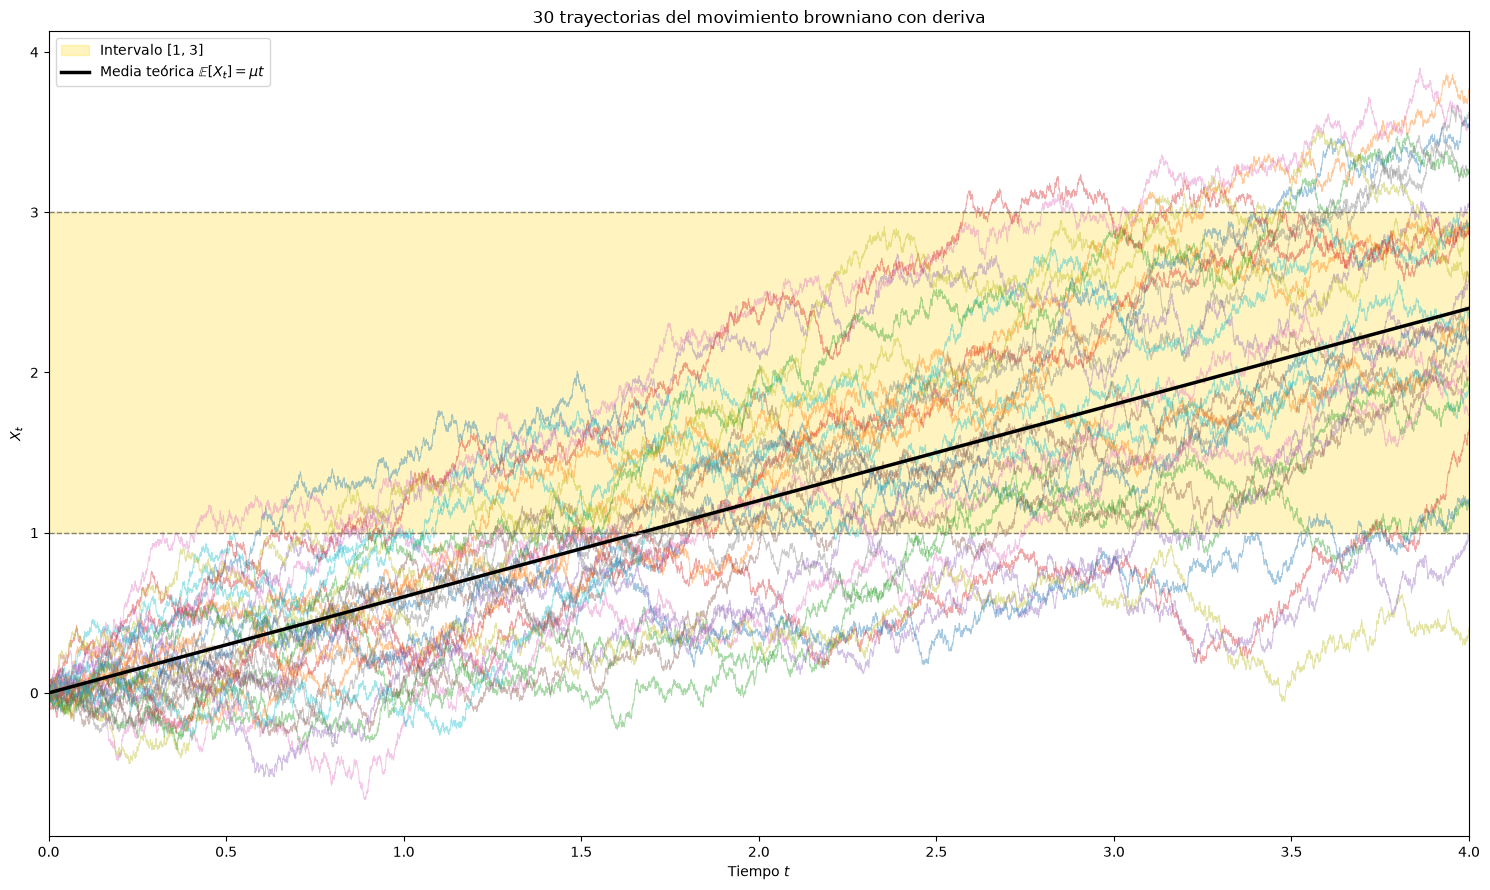

In [5]:
plt.figure(figsize=(15, 9))

# Franja del intervalo [1, 3].
plt.axhspan(1, 3, color="gold", alpha=0.25, label="Intervalo [1, 3]")

# Reutilizo las trayectorias guardadas y la misma malla de tiempos.
for trayectoria in trayectorias[:numero_a_graficar]:
    plt.plot(tiempos, trayectoria, linewidth=0.7, alpha=0.4)

# La media utiliza los parámetros ya definidos.
plt.plot(
    tiempos,
    mu * tiempos,
    color="black",
    linewidth=2.5,
    label=r"Media teórica $\mathbb{E}[X_t]=\mu t$"
)

plt.axhline(1, color="gray", linestyle="--", linewidth=1)
plt.axhline(3, color="gray", linestyle="--", linewidth=1)

plt.xlabel("Tiempo $t$")
plt.ylabel("$X_t$")
plt.title(f"{numero_a_graficar} trayectorias del movimiento browniano con deriva")
plt.xlim(0, T)
plt.legend()
plt.tight_layout()
plt.show()

## Probabilidad estimada y comparación

Contamos cuántos valores finales están entre 1 y 3 y dividimos entre el total de trayectorias. La estimación utiliza todos los `valores_finales`, incluidas las trayectorias mostradas en la gráfica.

In [6]:
casos_favorables = 0

for valor_final in valores_finales:
    if 1 < valor_final < 3:
        casos_favorables += 1

p_simulada = casos_favorables / len(valores_finales)

print(f"Valores finales entre 1 y 3: {casos_favorables}")
print(f"Probabilidad analítica: {p_analitica:.6f} ({100 * p_analitica:.3f}%)")
print(f"Probabilidad simulada:  {p_simulada:.6f} ({100 * p_simulada:.3f}%)")
print(f"Diferencia absoluta:    {abs(p_simulada - p_analitica):.6f}")

Valores finales entre 1 y 3: 64377
Probabilidad analítica: 0.644990 (64.499%)
Probabilidad simulada:  0.643770 (64.377%)
Diferencia absoluta:    0.001220


## Distribución de los valores finales

El histograma utiliza los mismos `valores_finales` con los que estimamos la probabilidad. La curva negra es la densidad teórica de $X_4$, el área naranja representa $P(1<X_4<3)$ y la línea vertical punteada indica su media.

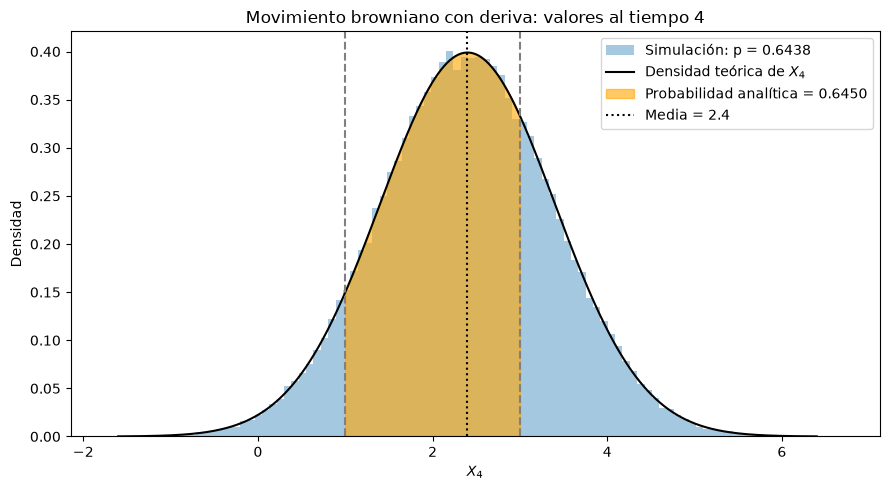

In [7]:
# Densidad teórica de X_4.
x = np.linspace(media - 4 * desviacion, media + 4 * desviacion, 1000)

plt.figure(figsize=(9, 5))

# Distribución de los valores finales obtenidos por simulación.
plt.hist(
    valores_finales,
    bins=100,
    density=True,
    alpha=0.4,
    label=f"Simulación: p = {p_simulada:.4f}"
)

# Curva de la distribución normal teórica.
plt.plot(
    x, norm.pdf(x, loc=media, scale=desviacion),
    color="black", label="Densidad teórica de $X_4$"
)

# Área correspondiente a P(1 < X_4 < 3).
intervalo = np.linspace(1, 3, 300)
plt.fill_between(
    intervalo,
    norm.pdf(intervalo, loc=media, scale=desviacion),
    color="orange",
    alpha=0.6,
    label=f"Probabilidad analítica = {p_analitica:.4f}"
)

plt.axvline(1, color="gray", linestyle="--")
plt.axvline(3, color="gray", linestyle="--")
plt.axvline(media, color="black", linestyle=":", label=f"Media = {media:.1f}")

plt.xlabel("$X_4$")
plt.ylabel("Densidad")
plt.title("Movimiento browniano con deriva: valores al tiempo 4")
plt.legend()
plt.tight_layout()
plt.show()